# 4 · Agente

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. El router de la lección 3 deja decidir al modelo una sola vez y termina con el resultado de la herramienta, que el modelo nunca lee. Esta lección cambia una arista, $\texttt{tools} \to \texttt{END}$, por $\texttt{tools} \to \texttt{modelo}$: el modelo lee cada resultado y vuelve a decidir, hasta que responde sin pedidos. Ese grafo es el agente.

La arista nueva cierra un ciclo, y con el ciclo vuelve la pregunta de la lección 1: ¿la ejecución termina? Se define el agente, se cuentan sus supersteps, se prueba que no tiene variante y se le agrega una guardia con `RemainingSteps`, que lo hace llegar a `END` por sí mismo, sin `GraphRecursionError`.

**Dónde corre.** Las secciones 1 a 5 y la profundización no usan el modelo y corren en el PC, con modelos guionados. La sección 6 usa `qwen3:8b`, que corre en Kaggle con una GPU; el [índice del módulo](README.md) explica cómo abrir el notebook allí.

Requisito: `pip install "langgraph>=1.2" "langchain-ollama>=1.1" "sympy>=1.14"`. Las salidas de este notebook son de langgraph 1.2.17, langgraph-prebuilt 1.1.1, langchain-core 1.7.0, langchain-ollama 1.1.0, sympy 1.14.0 y Ollama 0.40.13 con `qwen3:8b`, en una GPU T4 de Kaggle.

**Preparación.** En Kaggle, la celda siguiente instala las dependencias y Ollama, arranca el servidor y descarga `qwen3:8b`, en poco más de un minuto. En el PC no hace nada.

In [1]:
import os
import subprocess
import time
import urllib.request

EN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def correr(comando: str) -> None:
    """Corre un comando de shell y, si falla, muestra el final de su error."""
    r = subprocess.run(comando, shell=True, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"falló: {comando}\n{r.stderr[-2000:]}")


def preparar_kaggle() -> None:
    """Instala las dependencias y Ollama, arranca el servidor y descarga qwen3:8b."""
    correr("pip install -q 'langgraph==1.2.17' 'langgraph-prebuilt==1.1.1' 'langchain-core==1.7.0'"
           " 'langchain-ollama==1.1.0' 'sympy==1.14.0'")
    correr("(command -v zstd || (apt-get -qq update && apt-get -qq install -y zstd))"
           " && curl -fsSL https://ollama.com/install.sh | sh")
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        try:
            urllib.request.urlopen("http://127.0.0.1:11434/api/version")
            break
        except OSError:
            time.sleep(1)
    else:
        raise RuntimeError("el servidor de Ollama no respondió en 60 s")
    correr("ollama pull qwen3:8b")


if EN_KAGGLE:
    preparar_kaggle()

In [2]:
from importlib.metadata import version

for paquete in ("langgraph", "langgraph-prebuilt", "langchain-core", "langchain-ollama", "sympy"):
    print(paquete, version(paquete))

langgraph 1.2.17
langgraph-prebuilt 1.1.1
langchain-core 1.7.0
langchain-ollama 1.1.0
sympy 1.14.0


## 1. El problema

Por la Proposición 3.5, en el router el nodo del modelo corre una sola vez, antes de que exista cualquier respuesta de herramienta. Un pedido como «Deriva x³ y después integra el resultado» necesita dos decisiones, y la segunda depende del resultado de la primera: para pedir una primitiva de $3x^2$, el modelo tiene que haber leído $3x^2$. En la lección 3, `qwen3:8b` escribió los dos pedidos a la vez, los dos con $x^3$, y el router terminó en $x^4/4$.

Falta volver al modelo después de `tools`. Basta cambiar la arista fija $\texttt{tools} \to \texttt{END}$ del router por $\texttt{tools} \to \texttt{modelo}$. El grafo queda con un ciclo, $\texttt{modelo} \to \texttt{tools} \to \texttt{modelo}$, del que la ejecución sale por la arista condicional cuando el modelo responde sin pedidos.

**Mapa de la lección.** El agente con «Deriva x³ y después integra el resultado», un superstep a la vez. El grafo se define en la sección 2; la 3 cuenta sus supersteps, la 4 muestra que puede no terminar y la 5 le agrega la guardia que lo hace terminar. La sección 6 lo corre con el modelo.

<img src="../../imagenes/diagramas/modulo-1/agente.svg" alt="El agente: START lleva a modelo; de modelo, una arista condicional va a tools si el último mensaje trae pedidos y a END si no; tools vuelve a modelo. Con «Deriva x³ y después integra el resultado», el modelo pide derivar(x**3), tools escribe 3*x**2, el modelo lo lee y pide integrar(3*x**2), tools escribe x**3 y el modelo responde con texto, así que la ejecución va a END en el superstep 5" width="560">

Las herramientas, `linea` y el nodo `tools_seguro` son los de la lección 3:

In [3]:
from sympy import Symbol, diff, integrate, solve
from sympy.parsing.sympy_parser import convert_xor, parse_expr, standard_transformations

TRANSFORMACIONES = standard_transformations + (convert_xor,)


def leer(texto: str):
    """Convierte texto en sintaxis de SymPy en una expresión; «^» vale como potencia."""
    return parse_expr(texto, transformations=TRANSFORMACIONES)


def derivar(expresion: str, variable: str = "x") -> str:
    """Deriva una expresión respecto de una variable.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo x**2*sin(x).
        variable: variable respecto de la que se deriva.
    """
    return str(diff(leer(expresion), Symbol(variable)))


def integrar(expresion: str, variable: str = "x") -> str:
    """Calcula una primitiva de una expresión, sin constante de integración.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo 1/(1 + x**2).
        variable: variable de integración.
    """
    return str(integrate(leer(expresion), Symbol(variable)))


def resolver(ecuacion: str, variable: str = "x") -> str:
    """Resuelve una ecuación en una incógnita y devuelve la lista de soluciones.

    Args:
        ecuacion: ecuación en sintaxis de SymPy, por ejemplo x**2 - 2 = 0. Sin signo =, se iguala a cero.
        variable: incógnita.
    """
    izquierda, _, derecha = ecuacion.replace("==", "=").partition("=")  # «==», como en Python, vale como «=»
    return str(solve(leer(izquierda) - leer(derecha or "0"), Symbol(variable)))


HERRAMIENTAS = [derivar, integrar, resolver]

In [4]:
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.messages.tool import tool_call
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

tools_seguro = ToolNode(HERRAMIENTAS, handle_tool_errors=True)


def linea(m) -> str:
    """Rol y contenido de un mensaje; sus pedidos si es de rol ai, y su γ y estado si es de rol tool."""
    if m.type == "ai" and m.tool_calls:
        return "ai    pide " + ", ".join(f"{p['name']}({p['args']}) γ={p['id'][:8]}" for p in m.tool_calls)
    if m.type == "tool":
        return f"tool  {m.content!r}  γ={m.tool_call_id[:8]}  {m.status}"
    return f"{m.type:5} {m.content!r}"

## 2. El agente

**Definición 4.1 (agente).** Sean $\varphi_M$ el nodo de un modelo (lección 2, §6), $\varphi_H$ el nodo de herramientas con la respuesta de la Definición 3.2 y $c$ la arista `tools_condition` (Definición 3.3). El agente es el grafo con dos nodos, `modelo`, que corre $\varphi_M$, y `tools`, que corre $\varphi_H$, y tres aristas: la fija $\texttt{START} \to \texttt{modelo}$, la condicional $c$ desde `modelo` y la fija $\texttt{tools} \to \texttt{modelo}$.

Difiere del router en una sola arista. Desde `tools` ya no se llega a `END`: la única salida es que $c$ elija `END`, y eso ocurre cuando el último mensaje, que acaba de escribir el modelo, no trae pedidos. `construir_agente` recibe la función del nodo del modelo y, desde la sección 5, el esquema del estado.

In [5]:
def construir_agente(modelo, tools: ToolNode, esquema=MessagesState):
    """START → modelo; de modelo, a tools o a END según tools_condition; tools → modelo."""
    constructor = StateGraph(esquema)
    constructor.add_node("modelo", modelo)
    constructor.add_node("tools", tools)
    constructor.add_edge(START, "modelo")
    constructor.add_conditional_edges("modelo", tools_condition)
    constructor.add_edge("tools", "modelo")
    return constructor.compile()

Para probar el agente sin GPU hace falta un modelo guionado que cambie de mensaje según la conversación. El de la lección 3 no sirve: escribe siempre el mismo $m_0$, con el mismo identificador, así que en la segunda llamada $\oplus$ lo reemplaza en su lugar en vez de agregarlo (Definición 2.3). El último mensaje sigue siendo la respuesta de `tools`, $c$ elige `END`, y la ejecución termina en cuatro supersteps sin una respuesta del modelo. Por eso la Proposición 4.3 pedirá identificadores nuevos.

**Definición 4.2 (modelo guionado por turnos).** Sea $(m_1, \dots, m_q)$, con $q \ge 1$, una sucesión de mensajes de rol ai, y sea $a(c)$ la cantidad de mensajes de rol ai de una conversación $c$. El modelo guionado por turnos escribe $m_{a(c)+1}$ si $a(c) < q$, y $m_q$ si no. Como núcleo, $M(\cdot \mid c) = \delta_{m_j}$ con $j = \min(a(c) + 1, q)$.

Con $q = 1$ es el modelo guionado de la Definición 3.4. Si la entrada no tiene mensajes de rol ai y los $m_i$ tienen identificadores distintos, en el agente cada vez que el modelo corre encuentra un mensaje de rol ai más, así que el guion se lee en orden, desde $m_1$. El de abajo resuelve «Deriva x³ y después integra el resultado» en dos rondas, como debería hacerlo el modelo.

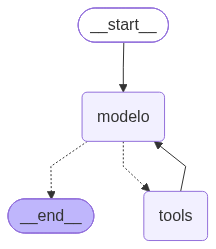

In [6]:
from IPython.display import Image, display


def por_turnos(*guion: AIMessage):
    """El nodo de un modelo guionado por turnos: si la conversación tiene i mensajes de rol ai, escribe guion[i]."""

    def modelo(s: MessagesState) -> dict:
        i = sum(1 for x in s["messages"] if x.type == "ai")
        return {"messages": [guion[min(i, len(guion) - 1)]]}

    return modelo


guion = (
    AIMessage("", id="m1", tool_calls=[tool_call(name="derivar", args={"expresion": "x**3"}, id="g1")]),
    AIMessage("", id="m2", tool_calls=[tool_call(name="integrar", args={"expresion": "3*x**2"}, id="g2")]),
    AIMessage("La derivada es 3*x**2, y una primitiva de 3*x**2 es x**3.", id="m3"),
)
agente = construir_agente(por_turnos(*guion), tools_seguro)
display(Image(agente.get_graph().draw_mermaid_png()))

La arista $\texttt{tools} \to \texttt{modelo}$ es continua porque es fija; las punteadas son las dos salidas de $c$. A diferencia del router, `tools` no tiene arista a `END`.

## 3. Cuántos supersteps usa

**Proposición 4.3 (ejecución del agente).** Sea $e \in C$ una entrada cuyos mensajes tienen identificador. Supóngase que, en sus llamadas sucesivas, el nodo del modelo escribe $m_1, m_2, \dots$, cada uno con un identificador que no aparece en la conversación que lee; que, para un $r \ge 0$, $m_1, \dots, m_r$ traen $k_1, \dots, k_r \ge 1$ pedidos, y que $m_{r+1}$ no trae pedidos. Sea $T_i = (t_{i,1}, \dots, t_{i,k_i})$ la sucesión de respuestas a los pedidos de $m_i$ (Definición 3.2). Cada par $(m_i, T_i)$ es una ronda, y $r$ es el número de rondas. Con `handle_tool_errors=True` y un `recursion_limit` de al menos $2r + 2$:

1. `modelo` corre en los supersteps impares $1, 3, \dots, 2r + 1$ y `tools` en los pares $2, 4, \dots, 2r$, así que la ejecución usa $2r + 2$ supersteps, contando el de `START`;
2. la conversación final es la de $e$ seguida de $m_1$, $T_1$, $m_2$, $T_2$, …, $m_r$, $T_r$ y $m_{r+1}$;
3. para $i = 0, \dots, r$, en el superstep $2i + 1$ el modelo lee una conversación que contiene $T_1, \dots, T_i$.

*Demostración.* Se prueba por inducción en $i = 1, \dots, r + 1$ que en el superstep $2i - 1$ corre solo `modelo` y que, al cerrarlo, la conversación es la de $e$ seguida de $m_1, T_1, \dots, m_{i-1}, T_{i-1}$ y $m_i$.

Para $i = 1$, el argumento es el de la Proposición 3.5: `START` escribe $e$ en el superstep 0 y `modelo` escribe $(m_1)$ en el 1, que se agrega al final porque su identificador no está en $\iota(e)$.

Supóngase cierto para un $i \le r$. Como $m_i$ trae pedidos, $c$ elige `tools`, y en el superstep $2i$ corre solo `tools`. Busca el último mensaje de rol ai, que es $m_i$, y escribe $T_i$; las respuestas reciben identificadores nuevos, así que $\oplus$ las agrega al final. La arista fija $\texttt{tools} \to \texttt{modelo}$ activa `modelo` en el superstep $2i + 1$, que lee esa conversación, con $T_1, \dots, T_i$, y escribe $m_{i+1}$, que también va al final. Eso prueba el paso y el punto 3.

Para $i = r + 1$, $m_{r+1}$ no trae pedidos y $c$ elige `END`, así que en el superstep $2r + 2$ no hay nodos activos. El último superstep es el $2r + 1$; con el de `START` son $2r + 2$, que `recursion_limit` permite. $\square$

Dos consecuencias. `tools` nunca corre dos veces seguidas: la única arista que entra a `tools` sale de `modelo`, y la única que sale de `tools` vuelve a `modelo`, así que entre dos rondas de herramientas siempre hay una llamada al modelo. Y la cuenta depende de las rondas, no de los pedidos: `tools` responde los $k_i$ pedidos de $m_i$ en un solo superstep (Profundización 3.A).

In [7]:
entrada = {"messages": [HumanMessage("Deriva x³ y después integra el resultado", id="h1")]}

print("después de START corren", [list(u) for u in agente.stream(entrada, stream_mode="updates")])
for x in agente.invoke(entrada)["messages"]:
    print(linea(x))

después de START corren [['modelo'], ['tools'], ['modelo'], ['tools'], ['modelo']]
human 'Deriva x³ y después integra el resultado'
ai    pide derivar({'expresion': 'x**3'}) γ=g1
tool  '3*x**2'  γ=g1  success
ai    pide integrar({'expresion': '3*x**2'}) γ=g2
tool  'x**3'  γ=g2  success
ai    'La derivada es 3*x**2, y una primitiva de 3*x**2 es x**3.'


Con $r = 2$ son seis supersteps: `START`, modelo, tools, modelo, tools, modelo. En el superstep 3, el modelo lee `3*x**2` antes de pedir `integrar`, que es lo que el router no podía hacer.

**Corolario 4.4.** Con las hipótesis de la Proposición 4.3, el menor `recursion_limit` con que la ejecución llega a `END` es $2r + 2$.

*Demostración.* Con $2r + 2$ llega, por la Proposición 4.3. Con un límite menor, la ejecución necesita más supersteps de los que el límite permite, y `GraphRecursionError` la detiene (Definición 1.15). $\square$

In [8]:
from langgraph.errors import GraphRecursionError

for limite in (5, 6):
    try:
        agente.invoke(entrada, {"recursion_limit": limite})
        print(f"recursion_limit = {limite}: llega a END")
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError")

recursion_limit = 5: GraphRecursionError
recursion_limit = 6: llega a END


## 4. ¿Termina?

En Euclides, el valor de $b$ era una variante (Proposición 1.17): un natural que baja en cada superstep. En el agente, lo que cambia en cada superstep es el largo de la conversación, y cambia hacia arriba: `modelo` agrega un mensaje y `tools`, uno por pedido. Que algo crezca no prueba nada. Una variante sirve porque baja en $\mathbb{N}$, y en $\mathbb{N}$ no se puede bajar para siempre; un largo que sube sí puede subir para siempre. Basta un modelo que pida herramientas en cada mensaje.

**Definición 4.5 (modelo insistente).** El modelo insistente escribe, con cualquier conversación, un mensaje de rol ai con un pedido, `derivar(x**3)`. El mensaje y el pedido llevan identificadores nuevos en cada llamada.

Antes de ejecutarlo, un detalle de cómo corta `recursion_limit`.

**Observación (el superstep $L$).** Sea $L$ el `recursion_limit`. En langgraph 1.2.17, el límite se revisa al comienzo de cada superstep (método `tick`, en `langgraph/pregel/_loop.py`), y la ejecución se detiene con `GraphRecursionError` en el primer superstep $t > L$, aunque ya no queden nodos activos. Los nodos activos en el superstep $L$ alcanzan a correr. Así, una ejecución llega a `END` si y solo si su último superstep con nodos activos es a lo más el $L - 1$, como dice la Definición 1.15, y cuando no llega, los nodos del superstep $L$ ya corrieron. Si uno de ellos es el modelo, es una llamada que no sirve.

**Proposición 4.6 (no hay variante).** Con el modelo insistente, la ejecución del agente no llega a `END` con ningún `recursion_limit` $L$: se detiene con `GraphRecursionError` después de $\lceil L/2 \rceil$ llamadas al modelo. En consecuencia, con el modelo insistente el agente no tiene variante (Definición 1.16), así que ninguna $V : S \to \mathbb{N}$ sirve para todo modelo.

*Demostración.* Cada mensaje del modelo insistente trae un pedido, así que $c$ elige siempre `tools`, y `tools` vuelve siempre a `modelo`: hay un nodo activo en todo superstep $t \ge 1$. Por la observación, corren los supersteps $1, \dots, L$ y la ejecución se detiene con `GraphRecursionError`. `modelo` corre en los impares de $\{1, \dots, L\}$, que son $\lceil L/2 \rceil$.

Si $V$ fuera una variante con este modelo, bajaría en cada superstep en que corre un nodo, y en $\mathbb{N}$ eso ocurre a lo más $V(s_0)$ veces. Con $L = V(s_0) + 1$, el último superstep con nodos activos sería a lo más el $V(s_0) = L - 1$, y la ejecución llegaría a `END`, contra la primera parte. $\square$

In [9]:
import uuid


def insistente(s: MessagesState) -> dict:
    """El nodo del modelo insistente: pide derivar(x**3) con cualquier conversación."""
    pedido = tool_call(name="derivar", args={"expresion": "x**3"}, id=str(uuid.uuid4()))
    return {"messages": [AIMessage("", id=str(uuid.uuid4()), tool_calls=[pedido])]}


def contar(nodo):
    """Envuelve el nodo de un modelo y cuenta sus llamadas en el atributo `llamadas`."""

    def envuelto(s: MessagesState) -> dict:
        envuelto.llamadas += 1
        return nodo(s)

    envuelto.llamadas = 0
    return envuelto


for limite in (6, 7, 25):
    modelo = contar(insistente)
    try:
        construir_agente(modelo, tools_seguro).invoke(entrada, {"recursion_limit": limite})
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError después de {modelo.llamadas} llamadas al modelo")

recursion_limit = 6: GraphRecursionError después de 3 llamadas al modelo
recursion_limit = 7: GraphRecursionError después de 4 llamadas al modelo
recursion_limit = 25: GraphRecursionError después de 13 llamadas al modelo


Con el valor por defecto, $L = 10\,007$, el modelo insistente correría $5\,004$ veces antes del error. Con `qwen3:8b`, que tarda segundos en cada llamada, serían horas de GPU para terminar en un error. Y `recursion_limit` corta la ejecución, pero no la termina: no llega a `END`, e `invoke` no devuelve ningún estado.

## 5. Pasos restantes

En la lección 1, la cota para Newton se puso en la arista (Proposición 1.19). En el agente no conviene: si $c$ eligiera `END` después de un mensaje con pedidos, la conversación terminaría con pedidos sin responder, como en la lección 2, y sin una respuesta para el usuario. La cota va en el nodo del modelo, que es el que decide si se piden herramientas, y para eso necesita saber cuántos supersteps quedan.

**Definición 4.7 (pasos restantes).** Sea $L$ el `recursion_limit` de una ejecución. Los pasos restantes en el superstep $t$ son $\lambda_t = L - t$. En LangGraph, una clave del esquema anotada con `RemainingSteps`, de `langgraph.managed`, es un valor administrado: ningún nodo la escribe, y el nodo que corre en el superstep $t$ la lee con valor $\lambda_t$ (`RemainingStepsManager`, en `langgraph/managed/is_last_step.py`).

`EstadoAgente` agrega la clave `pasos_restantes` a `MessagesState`. No aparece en el estado que devuelve `invoke`: solo la leen los nodos. Los pasos restantes son por invocación: con un checkpointer (lección 5), en cada `invoke` de un mismo hilo el primer nodo vuelve a leer $L - 1$.

In [10]:
from langgraph.managed import RemainingSteps


class EstadoAgente(MessagesState):
    pasos_restantes: RemainingSteps


def insistente_que_mira(s: EstadoAgente) -> dict:
    """El modelo insistente, que antes muestra los pasos restantes."""
    print("modelo lee pasos_restantes =", s["pasos_restantes"])
    return insistente(s)


try:
    construir_agente(insistente_que_mira, tools_seguro, EstadoAgente).invoke(entrada, {"recursion_limit": 7})
except GraphRecursionError:
    print("GraphRecursionError")

modelo lee pasos_restantes = 6
modelo lee pasos_restantes = 4
modelo lee pasos_restantes = 2
modelo lee pasos_restantes = 0
GraphRecursionError


Con $L = 7$, `modelo` corre en los supersteps 1, 3, 5 y 7 y lee $\lambda = 6, 4, 2, 0$. La última llamada es la del superstep $L$, que la observación de la sección 4 anticipaba.

Si el modelo pide herramientas en el superstep $t$, `tools` corre en el $t + 1$ y `modelo` en el $t + 2$. Para llegar a `END`, el superstep $t + 2$ tiene que ser a lo más el $L - 1$, es decir, $\lambda_t = L - t \ge 3$. Con menos pasos, pedir herramientas ya no sirve.

**Definición 4.8 (guardia).** Sea $\varphi_M$ el nodo de un modelo. El nodo con guardia toma la muestra $m$ de $\varphi_M$ en el superstep $t$. Si $m$ trae pedidos y $\lambda_t < 3$, escribe en su lugar un mensaje de rol ai sin pedidos, con el identificador de $m$ y el aviso «No alcancé a terminar: se acabaron los pasos.»; si no, escribe $m$.

**Proposición 4.9 (el agente con guardia termina).** Sea $L \ge 2$ el `recursion_limit`, y supóngase que las herramientas terminan y que cada mensaje que escribe el nodo del modelo tiene un identificador que no aparece en la conversación que lee. Con `handle_tool_errors=True` y el nodo con guardia, la ejecución del agente llega a `END` con todo modelo, en a lo más $L$ supersteps y sin `GraphRecursionError`. El modelo corre a lo más $\lfloor L/2 \rfloor$ veces.

*Demostración.* Por la forma del grafo, `modelo` corre en supersteps impares y `tools` en pares: a `tools` solo se llega desde `modelo`, y de `tools` solo se vuelve a `modelo`. Cada mensaje del modelo tiene un identificador nuevo, y el aviso lleva el del mensaje que reemplaza, así que $\oplus$ lo agrega al final y $c$ lo evalúa a él. Se prueba que todo superstep en que corre `modelo` cumple $\lambda_t \ge 1$. El primero es el 1, con $\lambda_1 = L - 1 \ge 1$. Si `modelo` corre en el superstep $t$ y escribe un mensaje sin pedidos, $c$ elige `END`. Si lo escribe con pedidos, la guardia no actuó, así que $\lambda_t \ge 3$: `tools` corre en el $t + 1$, con $\lambda_{t+1} \ge 2$, y `modelo` en el $t + 2$, con $\lambda_{t+2} = \lambda_t - 2 \ge 1$.

Entonces todo superstep con nodos activos cumple $t \le L - 1$. Hay finitos, así que la ejecución deja de tener nodos activos, y por la observación de la sección 4 llega a `END` en a lo más $L$ supersteps, sin `GraphRecursionError`. `modelo` corre en impares menores que $L$, que son $\lfloor L/2 \rfloor$. $\square$

Los pasos restantes bajan en 1 en cada superstep, como una variante, pero no son función del estado: bajan haga lo que haga el modelo, y si al llegar a 0 todavía hay nodos activos, la ejecución no sale por `END`, sino con `GraphRecursionError`. Lo que los convierte en una cota de terminación es la guardia, que los lee y hace que $c$ elija `END` a tiempo.

In [11]:
AVISO = "No alcancé a terminar: se acabaron los pasos."


def con_guardia(modelo, umbral: int = 3):
    """El nodo del modelo con guardia: si quedan menos de `umbral` pasos, cambia un mensaje con pedidos por AVISO."""

    def nodo(s: EstadoAgente) -> dict:
        m = modelo(s)["messages"][-1]
        if m.tool_calls and s["pasos_restantes"] < umbral:
            m = AIMessage(AVISO, id=m.id)
        return {"messages": [m]}

    return nodo


for limite in range(2, 10):
    modelo = contar(insistente)
    final = construir_agente(con_guardia(modelo), tools_seguro, EstadoAgente).invoke(entrada, {"recursion_limit": limite})
    print(f"recursion_limit = {limite}: llega a END; llamadas al modelo = {modelo.llamadas}")
print("último mensaje:", repr(final["messages"][-1].content))

recursion_limit = 2: llega a END; llamadas al modelo = 1
recursion_limit = 3: llega a END; llamadas al modelo = 1
recursion_limit = 4: llega a END; llamadas al modelo = 2
recursion_limit = 5: llega a END; llamadas al modelo = 2
recursion_limit = 6: llega a END; llamadas al modelo = 3
recursion_limit = 7: llega a END; llamadas al modelo = 3
recursion_limit = 8: llega a END; llamadas al modelo = 4
recursion_limit = 9: llega a END; llamadas al modelo = 4
último mensaje: 'No alcancé a terminar: se acabaron los pasos.'


El modelo insistente pide herramientas en todos sus mensajes, y aun así el agente llega a `END` con todo límite, después de $\lfloor L/2 \rfloor$ llamadas y con el aviso al final. La guardia, además, solo actúa en ejecuciones que sin ella terminarían en `GraphRecursionError`.

**Proposición 4.10 (la guardia no cambia lo que terminaba).** Fijada la sucesión de mensajes $m_1, m_2, \dots$ que escribe el modelo, con identificadores como en la Proposición 4.3, si la ejecución sin guardia llega a `END` con `recursion_limit` $L$, la ejecución con guardia escribe los mismos mensajes y termina en el mismo estado.

*Demostración.* Por la Proposición 4.3 y el Corolario 4.4, sin guardia hay $r$ rondas, con $2r + 2 \le L$. El mensaje $m_i$, con $i \le r$, se escribe en el superstep $2i - 1$, con $\lambda = L - 2i + 1 \ge 2(r - i) + 3 \ge 3$. La guardia no cambia ninguno de esos mensajes, y $m_{r+1}$ no trae pedidos, así que tampoco lo cambia. $\square$

Con el guion de la sección 3, que necesita $L = 6$:

In [12]:
for limite in (5, 6):
    agente_con_guardia = construir_agente(con_guardia(por_turnos(*guion)), tools_seguro, EstadoAgente)
    print(f"recursion_limit = {limite}:")
    for x in agente_con_guardia.invoke(entrada, {"recursion_limit": limite})["messages"][1:]:
        print("   ", linea(x))

recursion_limit = 5:
    ai    pide derivar({'expresion': 'x**3'}) γ=g1
    tool  '3*x**2'  γ=g1  success
    ai    'No alcancé a terminar: se acabaron los pasos.'
recursion_limit = 6:
    ai    pide derivar({'expresion': 'x**3'}) γ=g1
    tool  '3*x**2'  γ=g1  success
    ai    pide integrar({'expresion': '3*x**2'}) γ=g2
    tool  'x**3'  γ=g2  success
    ai    'La derivada es 3*x**2, y una primitiva de 3*x**2 es x**3.'


Con $L = 5$, el modelo pide `integrar` en el superstep 3, con $\lambda = 2$, y la guardia cambia ese mensaje por el aviso; sin ella, la ejecución terminaba en `GraphRecursionError` (Corolario 4.4). Con $L = 6$, el pedido llega con $\lambda = 3$ y el resultado es el de la sección 3.

Las dos ejecuciones con el modelo insistente y $L = 7$, sin guardia y con ella:

<img src="../../imagenes/diagramas/modulo-1/pasos-restantes.svg" alt="Dos filas de supersteps con recursion_limit = 7 y el modelo insistente. Hasta el superstep 4 son iguales, con los pasos restantes bajando de 6 a 3. En el superstep 5, con λ = 2, sin guardia el modelo pide herramientas, tools corre en el 6 y el modelo en el 7 con λ = 0, y la ejecución termina en GraphRecursionError; con guardia, el modelo escribe el aviso sin pedidos y la ejecución llega a END en seis supersteps" width="640">

**Observación (`create_react_agent`).** El agente prearmado de `langgraph.prebuilt`, `create_react_agent`, trae esta guardia con la clave `remaining_steps`, pero con umbral 2: cambia el mensaje si $\lambda_t < 2$ (función `_are_more_steps_needed`, en `langgraph/prebuilt/chat_agent_executor.py`). Con ese umbral, la Proposición 4.9 falla para algunos $L$; el ejercicio 3 pide encontrarlos. En langgraph 1.x, `create_react_agent` está marcado como obsoleto, en favor de `create_agent`, de `langchain.agents`.

## 6. El agente con `qwen3:8b`

El nodo del modelo es el de la lección 3, con la guardia, y el límite es $L = 12$: alcanza para cinco rondas de herramientas (Corolario 4.4) y el modelo corre a lo más seis veces (Proposición 4.9). `pedir` cuenta los supersteps con `stream_mode="values"`, que entrega un estado por superstep, el de `START` incluido (Propiedad 1.13). La primera llamada carga el modelo en la GPU y tarda más de un minuto.

In [13]:
from langchain_core.messages import SystemMessage
from langchain_ollama import ChatOllama

SISTEMA = SystemMessage(
    "Eres un asistente de cálculo. Para derivar, integrar o resolver ecuaciones usa las herramientas. "
    "Escribe las expresiones en sintaxis de SymPy, por ejemplo x**2*sin(x)."
)
llm = ChatOllama(model="qwen3:8b", temperature=0, reasoning=False)
llm_con_herramientas = llm.bind_tools(HERRAMIENTAS)


def modelo(s: MessagesState) -> dict:
    """Toma una muestra del modelo con (σ) ⁀ s(messages)."""
    return {"messages": [llm_con_herramientas.invoke([SISTEMA] + s["messages"])]}


def pedir(agente, pedido: str, limite: int = 12) -> None:
    """Corre el agente con un pedido; muestra cuántos supersteps usó y los mensajes que agregó."""
    estados = list(agente.stream({"messages": [HumanMessage(pedido)]}, {"recursion_limit": limite}, stream_mode="values"))
    print(f"{pedido}  →  {len(estados)} supersteps")
    for x in estados[-1]["messages"][1:]:
        print("   ", linea(x))


agente = construir_agente(con_guardia(modelo), tools_seguro, EstadoAgente)

Los pedidos de la lección 3, ahora con el agente:

In [14]:
for pedido in ["Deriva x^2·sen(x)", "Integra 1/(1+x^2)", "Resuelve x^2 - 2 = 0", "¿Cuánto es 2 + 2?"]:
    pedir(agente, pedido)

Deriva x^2·sen(x)  →  4 supersteps
    ai    pide derivar({'expresion': 'x**2*sin(x)', 'variable': 'x'}) γ=b92b4cb9
    tool  'x**2*cos(x) + 2*x*sin(x)'  γ=b92b4cb9  success
    ai    'La derivada de $ x^2 \\cdot \\sen(x) $ es:\n\n$$\nx^2 \\cos(x) + 2x \\sen(x)\n$$'
Integra 1/(1+x^2)  →  4 supersteps
    ai    pide integrar({'expresion': '1/(1 + x**2)', 'variable': 'x'}) γ=9e880030
    tool  'atan(x)'  γ=9e880030  success
    ai    'La integral de $ \\frac{1}{1 + x^2} $ es $ \\arctan(x) + C $, donde $ C $ es la constante de integración.'
Resuelve x^2 - 2 = 0  →  4 supersteps
    ai    pide resolver({'ecuacion': 'x**2 - 2', 'variable': 'x'}) γ=0a16bdf9
    tool  '[-sqrt(2), sqrt(2)]'  γ=0a16bdf9  success
    ai    'Las soluciones de la ecuación $ x^2 - 2 = 0 $ son:\n\n$$\nx = -\\sqrt{2} \\quad \\text{y} \\quad x = \\sqrt{2}\n$$'
¿Cuánto es 2 + 2?  →  2 supersteps
    ai    '2 + 2 es igual a 4.'


Cada pedido con herramienta usa ahora cuatro supersteps, una ronda: después de `tools`, el modelo lee el resultado y responde con texto, en LaTeX. En el router, la ejecución terminaba con el mensaje de herramienta; aquí termina con el modelo. «¿Cuánto es 2 + 2?» no pide herramientas y usa dos supersteps, como en el router. En la primera respuesta, el modelo escribió `\sen`, que no es un comando de LaTeX: copió la notación del pedido, aunque la herramienta respondió con `sin`.

El pedido en dos pasos:

In [15]:
pedir(agente, "Deriva x³ y después integra el resultado")

Deriva x³ y después integra el resultado  →  4 supersteps
    ai    pide derivar({'expresion': 'x**3', 'variable': 'x'}) γ=ad832bf6, integrar({'expresion': 'x**3', 'variable': 'x'}) γ=3ba0b028
    tool  '3*x**2'  γ=ad832bf6  success
    tool  'x**4/4'  γ=3ba0b028  success
    ai    'La derivada de $ x^3 $ es $ 3x^2 $, y la integral de $ 3x^2 $ es $ \\frac{x^4}{4} $.'


El agente no lo arregla. El modelo escribió los dos pedidos en el mismo mensaje, los dos con `x**3`, como en el router de la lección 3: una sola ronda y cuatro supersteps. Después leyó las dos respuestas y escribió algo falso: que la integral de $3x^2$ es $x^4/4$, cuando `x**4/4` es una primitiva de $x^3$. La arista $\texttt{tools} \to \texttt{modelo}$ le permite leer cada resultado antes de seguir, pero no lo obliga a esperarlo: el modelo decide cuántos pedidos escribe en cada mensaje.

El nodo del modelo toma una muestra de $M(\cdot \mid (\sigma) \frown s(\text{messages}))$, así que cambiar el mensaje de sistema $\sigma$ cambia la distribución de lo que escribe el modelo, sin tocar el grafo. Con una instrucción más, $\sigma'$:

In [16]:
SISTEMA_PASOS = SystemMessage(
    SISTEMA.content + " Si un cálculo necesita el resultado de otro, pide primero ese y espera su resultado."
)


def modelo_por_pasos(s: MessagesState) -> dict:
    """Toma una muestra del modelo con (σ') ⁀ s(messages), donde σ' pide esperar los resultados."""
    return {"messages": [llm_con_herramientas.invoke([SISTEMA_PASOS] + s["messages"])]}


pedir(construir_agente(con_guardia(modelo_por_pasos), tools_seguro, EstadoAgente), "Deriva x³ y después integra el resultado")

Deriva x³ y después integra el resultado  →  6 supersteps
    ai    pide derivar({'expresion': 'x**3', 'variable': 'x'}) γ=488db07b
    tool  '3*x**2'  γ=488db07b  success
    ai    pide integrar({'expresion': '3*x**2', 'variable': 'x'}) γ=49eba832
    tool  'x**3'  γ=49eba832  success
    ai    'La derivada de $ x^3 $ es $ 3x^2 $, y la integral de $ 3x^2 $ es $ x^3 $.'


Con $\sigma'$, el modelo pidió `derivar(x**3)`, leyó `3*x**2` y recién entonces pidió `integrar(3*x**2)`: dos rondas y seis supersteps, como el guion de la sección 3, y la respuesta correcta, $x^3$. El grafo es el mismo en las dos ejecuciones; lo que cambió fue el núcleo.

Un pedido en que el segundo paso comprueba el primero:

In [17]:
pedir(agente, "Integra x·cos(x) y comprueba el resultado derivándolo")

Integra x·cos(x) y comprueba el resultado derivándolo  →  6 supersteps
    ai    pide integrar({'expresion': 'x*cos(x)', 'variable': 'x'}) γ=41fe2645
    tool  'x*sin(x) + cos(x)'  γ=41fe2645  success
    ai    pide derivar({'expresion': 'x*sin(x) + cos(x)', 'variable': 'x'}) γ=901980a2
    tool  'x*cos(x)'  γ=901980a2  success
    ai    'La derivada de $ x \\sin(x) + \\cos(x) $ es $ x \\cos(x) $, lo cual coincide con la función original. Por lo tanto, el resultado de la integración es correcto.'


Aquí el segundo paso necesita el resultado del primero por la forma misma del pedido, y el modelo lo hizo en dos rondas con el mensaje de sistema original: integró, leyó `x*sin(x) + cos(x)` y derivó esa expresión. Son seis supersteps, y la comprobación es correcta: la derivada de $x \sin x + \cos x$ es $x \cos x$.

El mismo pedido con $L = 4$:

In [18]:
pedir(agente, "Integra x·cos(x) y comprueba el resultado derivándolo", limite=4)

Integra x·cos(x) y comprueba el resultado derivándolo  →  4 supersteps
    ai    pide integrar({'expresion': 'x*cos(x)', 'variable': 'x'}) γ=d23508d2
    tool  'x*sin(x) + cos(x)'  γ=d23508d2  success
    ai    'No alcancé a terminar: se acabaron los pasos.'


Con $L = 4$, el modelo pide `integrar` en el superstep 1, con $\lambda = 3$, y `tools` responde en el 2. En el superstep 3, con $\lambda = 1$, el modelo vuelve a pedir herramientas, y la guardia cambia ese mensaje por el aviso: la ejecución llega a `END` en cuatro supersteps, con la primitiva calculada pero sin comprobar. Con las mismas muestras y sin la guardia, `tools` habría corrido en el superstep 4 y la ejecución habría terminado en `GraphRecursionError` al pasar al superstep 5, sin llegar a `END`.

### Profundización 4.A · Cuántas rondas

La guardia asegura que el agente termina, pero no dice cuántas rondas usa ni con qué probabilidad la guardia actúa. Con el modelo como núcleo (Definición 2.7), esas preguntas tienen respuesta.

**Definición 4.A.1 (rondas).** Sea $Q$ el conjunto de los mensajes de rol ai que traen al menos un pedido. En una ejecución del agente sin límite, sea $c_i$ la sucesión que recibe el modelo en su llamada $i$ y $m_i \sim M(\cdot \mid c_i)$ el mensaje que escribe. El número de rondas es

$$R = \min\{i \ge 1 : m_i \notin Q\} - 1,$$

con $R = \infty$ si el modelo nunca deja de pedir.

En adelante, cada mensaje del modelo tiene un identificador nuevo, como en la Proposición 4.3; así, si $R < \infty$, la ejecución sin guardia usa $2R + 2$ supersteps.

**Proposición 4.A.2.** Si existe $p < 1$ con $M(Q \mid c) \le p$ para toda sucesión $c$, entonces $P(R \ge r) \le p^r$ para todo $r \in \mathbb{N}$. En particular, la ejecución sin límite llega a `END` con probabilidad 1, y $E[R] \le p/(1 - p)$.

*Demostración.* $R \ge r + 1$ si y solo si $R \ge r$ y $m_{r+1} \in Q$. Si $R \ge r$, la llamada $r + 1$ ocurre, y dado todo lo anterior, $m_{r+1}$ se toma de $M(\cdot \mid c_{r+1})$, que le da a $Q$ probabilidad a lo más $p$. Entonces

$$P(R \ge r + 1) \le p \, P(R \ge r),$$

y como $P(R \ge 0) = 1$, por inducción $P(R \ge r) \le p^r$. Así $P(R = \infty) \le \lim_r p^r = 0$, y

$$E[R] = \sum_{r \ge 1} P(R \ge r) \le \frac{p}{1 - p}.$$

$\square$

**Proposición 4.A.3 (la cota se alcanza).** Si $M(Q \mid c) = p$ para toda $c$, con $p < 1$, entonces $R$ tiene distribución geométrica: $P(R \ge r) = p^r$, $P(R = r) = p^r (1 - p)$ y $E[R] = p/(1 - p)$.

*Demostración.* Las desigualdades de la demostración anterior son igualdades, y $P(R = r) = P(R \ge r) - P(R \ge r + 1)$. $\square$

Un modelo que pide herramientas con probabilidad $p$, sin mirar la conversación, cumple la hipótesis con igualdad. Con $p = 0{,}7$ y 2000 ejecuciones:

In [19]:
import random


def aleatorio(p: float, rng: random.Random):
    """El nodo de un modelo que pide derivar(x**3) con probabilidad p y, si no, responde con texto."""

    def modelo(s: MessagesState) -> dict:
        if rng.random() < p:
            return insistente(s)
        return {"messages": [AIMessage("listo", id=str(uuid.uuid4()))]}

    return modelo


def rondas(final: dict) -> int:
    """Rondas de una ejecución que llegó a END: sus mensajes de rol ai, menos el último."""
    return sum(1 for x in final["messages"] if x.type == "ai") - 1


P, N = 0.7, 2000
agente_aleatorio = construir_agente(aleatorio(P, random.Random(0)), tools_seguro)
muestra = [rondas(agente_aleatorio.invoke(entrada, {"recursion_limit": 200})) for _ in range(N)]

print(" r   frecuencia de R ≥ r   p^r")
for r in range(9):
    print(f"{r:2}   {sum(x >= r for x in muestra) / N:.3f}                 {P**r:.3f}")
print(f"media de R: {sum(muestra) / N:.3f}; p/(1 − p) = {P / (1 - P):.3f}")

 r   frecuencia de R ≥ r   p^r
 0   1.000                 1.000
 1   0.690                 0.700
 2   0.472                 0.490
 3   0.340                 0.343
 4   0.236                 0.240
 5   0.168                 0.168
 6   0.120                 0.118
 7   0.085                 0.082
 8   0.057                 0.058
media de R: 2.297; p/(1 − p) = 2.333


Con $L = 200$, una ejecución sin guardia falla solo si $R \ge 100$, lo que tiene probabilidad $0{,}7^{100} \approx 3 \cdot 10^{-16}$. El Corolario 4.A.4 da el $L$ que hace falta para todo $p$ y $\delta$.

**Corolario 4.A.4 (elegir el límite).** Sean $L \ge 2$, $0 < p < 1$ y $0 < \delta < 1$. Con la hipótesis de la Proposición 4.A.2 y `recursion_limit` $L$, sin guardia la ejecución termina en `GraphRecursionError` si y solo si $R \ge \lfloor L/2 \rfloor$, lo que tiene probabilidad a lo más $p^{\lfloor L/2 \rfloor}$. Con guardia, la guardia actúa con esa misma probabilidad, $P(R \ge \lfloor L/2 \rfloor)$. Para que sea a lo más $\delta$, basta que $\lfloor L/2 \rfloor \ge \ln \delta / \ln p$.

*Demostración.* Las ejecuciones sin límite, con límite $L$ y con guardia se construyen con el mismo azar: las mismas muestras del modelo y los mismos identificadores. Hasta que una se corta o actúa la guardia, las tres le pasan al modelo la misma conversación $c_i$, así que la muestra compartida tiene en cada una la distribución $M(\cdot \mid c_i)$, y cada ejecución tiene su distribución. Con este acoplamiento, por la Proposición 4.3 y el Corolario 4.4, sin guardia la ejecución llega a `END` si y solo si $2R + 2 \le L$, es decir, $R \le \lfloor L/2 \rfloor - 1$. Falla si $R \ge \lfloor L/2 \rfloor$, con probabilidad a lo más $p^{\lfloor L/2 \rfloor}$ (Proposición 4.A.2). La guardia actúa exactamente en las ejecuciones que fallan: no actúa en las que llegan a `END` (Proposición 4.10), y en las demás tiene que actuar, porque si no la ejecución sería la misma que sin guardia y terminaría en `GraphRecursionError`, contra la Proposición 4.9. Por último, como $\ln p < 0$, $p^k \le \delta$ si y solo si $k \ge \ln \delta / \ln p$. $\square$

Con $p = 0{,}7$ y $L = 8$, la cota es $0{,}7^4 \approx 0{,}24$, y con este modelo se alcanza (Proposición 4.A.3):

In [20]:
import math

agente_aleatorio = construir_agente(con_guardia(aleatorio(P, random.Random(1))), tools_seguro, EstadoAgente)
avisos = sum(agente_aleatorio.invoke(entrada, {"recursion_limit": 8})["messages"][-1].content == AVISO for _ in range(N))
print(f"L = 8: la guardia actuó en {avisos / N:.3f} de las ejecuciones; p^4 = {P**4:.3f}")

print("\n p     menor L con cota ≤ 10⁻³   menor L con cota ≤ 10⁻⁶")
for p in (0.5, 0.7, 0.9):
    menores = [2 * math.ceil(math.log(delta) / math.log(p)) for delta in (1e-3, 1e-6)]
    print(f"{p}   {menores[0]:>10}                {menores[1]:>10}")

L = 8: la guardia actuó en 0.240 de las ejecuciones; p^4 = 0.240

 p     menor L con cota ≤ 10⁻³   menor L con cota ≤ 10⁻⁶
0.5           20                        40
0.7           40                        78
0.9          132                       264


El menor $L$ es $2k$, con $k = \lceil \ln \delta / \ln p \rceil$. Crece como $\ln(1/\delta)$ cuando $\delta$ baja: dividir $\delta$ por mil suma unos $2 \ln 1000 / (-\ln p)$ supersteps, que en la tabla son 20 con $p = 0{,}5$, 38 con $p = 0{,}7$ y 132 con $p = 0{,}9$. Y crece como $1/(1 - p)$ cuando $p$ se acerca a 1, porque $-\ln p \approx 1 - p$: el costo de bajar $\delta$ se suma, pero multiplicado por $1/(-\ln p)$.

<img src="../../imagenes/figuras/modulo-1/cola.svg" alt="La cota p^r de P(R ≥ r) en escala logarítmica, para p = 0,5, 0,7 y 0,9: tres rectas que bajan desde 1, y la línea horizontal δ = 10⁻³. El primer r con p^r ≤ δ es 10, 20 y 66, que dan los límites L = 20, 40 y 132" width="640">

**Observación (cuándo vale la hipótesis).** La Proposición 4.A.2 pide la misma cota $p$ para toda conversación, y eso no se puede comprobar para `qwen3:8b`. Con `temperature=0`, además, el muestreo es casi determinista: si desde alguna conversación el modelo entra en un ciclo en que vuelve a pedir lo mismo, $M(Q \mid c)$ vale 1, o casi, en cada vuelta y el agente se comporta como el modelo insistente. La proposición sirve para razonar sobre el límite; la que garantiza que el agente termina es la guardia.

## Resumen

- El **agente** es el router con la arista $\texttt{tools} \to \texttt{modelo}$ en lugar de $\texttt{tools} \to \texttt{END}$. El modelo lee cada respuesta de herramienta y vuelve a decidir, y la única salida del ciclo es que `tools_condition` vea un mensaje sin pedidos.
- Si el modelo usa $r$ rondas de herramientas, la ejecución usa $2r + 2$ supersteps: `modelo` en los impares y `tools` en los pares, nunca dos veces seguidas, con cualquier cantidad de pedidos por mensaje (Proposición 4.3). El menor `recursion_limit` que alcanza es $2r + 2$.
- Con el modelo insistente, el agente no tiene variante: el largo de la conversación crece para siempre. Con `recursion_limit` $L$, los nodos del superstep $L$ alcanzan a correr antes de `GraphRecursionError`, así que el modelo insistente corre $\lceil L/2 \rceil$ veces; con el valor por defecto, $5\,004$.
- El nodo que corre en el superstep $t$ lee $\lambda_t = L - t$ en una clave anotada con `RemainingSteps`. La **guardia** cambia un mensaje con pedidos por un aviso si $\lambda_t < 3$. Con ella el agente llega a `END` con todo modelo, en a lo más $L$ supersteps y $\lfloor L/2 \rfloor$ llamadas al modelo (Proposición 4.9), y no cambia las ejecuciones que ya terminaban (Proposición 4.10). El umbral 2 de `create_react_agent` no alcanza para todo $L$.
- Con `qwen3:8b`, el agente resuelve en dos rondas un pedido cuyo segundo paso depende del primero, como comprobar una primitiva derivándola. El ciclo permite leer cada resultado, pero no obliga a esperarlo: con «Deriva x³ y después integra el resultado», el modelo pidió las dos herramientas a la vez y respondió algo falso, hasta que un mensaje de sistema le pidió esperar los resultados.
- Si cada llamada pide herramientas con probabilidad a lo más $p < 1$, las rondas cumplen $P(R \ge r) \le p^r$, la ejecución sin límite llega a `END` con probabilidad 1 y $E[R] \le p/(1 - p)$. La guardia actúa con probabilidad a lo más $p^{\lfloor L/2 \rfloor}$, y el $L$ que hace falta crece como $1/(1 - p)$ y como $\ln(1/\delta)$ (Profundización 4.A).

La lección 5 guarda la sucesión de estados de una ejecución, un checkpoint por superstep, y la retoma en el mismo hilo: el agente con memoria.

## Ejercicios

**Ejercicio 1 (mensajes y supersteps).** Con las hipótesis de la Proposición 4.3 y una entrada de $n$ mensajes, ¿cuántos mensajes tiene la conversación final? Si $r \ge 1$ y el modelo escribiera los $k_1 + \cdots + k_r$ pedidos en un solo mensaje, y después la respuesta, ¿cuántos supersteps usaría la ejecución y cuántos mensajes tendría al final?

*Pista:* cada superstep de `modelo` agrega un mensaje, y cada superstep de `tools`, uno por pedido.

<details>
<summary>Solución</summary>

La conversación final tiene $n + (r + 1) + (k_1 + \cdots + k_r)$ mensajes: los de $e$, los $r + 1$ del modelo y una respuesta por pedido. Con todos los pedidos en un mensaje hay una sola ronda, así que la ejecución usa $2 \cdot 1 + 2 = 4$ supersteps, y la conversación final tiene $n + 2 + (k_1 + \cdots + k_r)$ mensajes: dos del modelo en lugar de $r + 1$. Pedir todo junto ahorra supersteps y llamadas al modelo, pero solo sirve si ningún pedido necesita el resultado de otro, que es lo que falló en el router de la lección 3.

```python
juntos = (
    AIMessage("", id="j1", tool_calls=[
        tool_call(name="derivar", args={"expresion": "x**3"}, id="p1"),
        tool_call(name="integrar", args={"expresion": "x**2"}, id="p2"),
        tool_call(name="resolver", args={"ecuacion": "x**2 - 2 = 0"}, id="p3"),
    ]),
    AIMessage("listo", id="j2"),
)
agente_juntos = construir_agente(por_turnos(*juntos), tools_seguro)
print(len(list(agente_juntos.stream(entrada, stream_mode="values"))), "supersteps,",
      len(agente_juntos.invoke(entrada)["messages"]), "mensajes")
```

</details>

**Ejercicio 2 (un error que el modelo corrige).** Escribir un guion por turnos en que el modelo pida `derivar("x^^3")`, que SymPy no puede leer, después `derivar("x**3")`, y al final responda con texto. Predecir cuántos supersteps usa el agente y qué `status` tiene cada mensaje de herramienta, y comprobarlo. ¿Cómo terminaría el router de la lección 3 con el mismo guion?

*Pista:* lección 3, §3. Con `handle_tool_errors=True`, un pedido que falla también tiene respuesta.

<details>
<summary>Solución</summary>

Son dos rondas, así que el agente usa $2 \cdot 2 + 2 = 6$ supersteps (Proposición 4.3). El primer mensaje de herramienta tiene `status="error"` y describe el `SyntaxError`; el segundo, `status="success"` y contenido `3*x**2`. El modelo lee el error en el superstep 3, antes de su segundo pedido. El router, en cambio, termina después de la primera ronda, en tres supersteps, con el mensaje de error al final: el modelo nunca lo lee y no puede corregir la expresión (Proposición 3.5).

```python
corrige = (
    AIMessage("", id="c1", tool_calls=[tool_call(name="derivar", args={"expresion": "x^^3"}, id="q1")]),
    AIMessage("", id="c2", tool_calls=[tool_call(name="derivar", args={"expresion": "x**3"}, id="q2")]),
    AIMessage("La derivada de x³ es 3*x**2.", id="c3"),
)
agente_corrige = construir_agente(por_turnos(*corrige), tools_seguro)
print(len(list(agente_corrige.stream(entrada, stream_mode="values"))), "supersteps")
for x in agente_corrige.invoke(entrada)["messages"]:
    if x.type == "tool":
        print(x.status, repr(x.content[:40]))
```

</details>

**Ejercicio 3 (el umbral de `create_react_agent`).** Con `con_guardia(insistente, umbral=2)`, ¿para qué valores de $L \ge 2$ termina la ejecución en `GraphRecursionError`? Demostrarlo y comprobarlo para $L = 2, \dots, 9$.

*Pista:* `modelo` corre en los supersteps impares. ¿Con qué $\lambda$ corre la última llamada que pide herramientas?

<details>
<summary>Solución</summary>

Termina en `GraphRecursionError` si y solo si $L$ es impar. `modelo` corre en supersteps impares $t$, con $\lambda_t = L - t$, y con umbral 2 la guardia deja pedir herramientas mientras $\lambda_t \ge 2$.

Si $L$ es par, los $\lambda_t$ de `modelo` son impares: $L - 1, L - 3, \dots, 1$. El primero menor que 2 es $\lambda = 1$, en el superstep $L - 1$: la guardia escribe el aviso y la ejecución llega a `END` sin exceder el límite.

Si $L$ es impar, los $\lambda_t$ de `modelo` son pares: $L - 1, \dots, 2, 0$. Con $\lambda = 2$, en el superstep $L - 2$, la guardia deja pedir; `tools` corre en el $L - 1$ y `modelo` en el $L$, con $\lambda = 0$. Ahí la guardia escribe el aviso, pero el superstep $L$ ya corrió y la ejecución se detiene con `GraphRecursionError` (observación de la sección 4). Es lo que hace `create_react_agent` con un modelo que siempre pide herramientas. Con umbral 3 no ocurre (Proposición 4.9).

```python
for limite in range(2, 10):
    try:
        construir_agente(con_guardia(insistente, umbral=2), tools_seguro, EstadoAgente).invoke(entrada, {"recursion_limit": limite})
        print(f"recursion_limit = {limite}: END")
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError")
```

</details>

**Ejercicio 4 (elegir el límite).** Un modelo pide herramientas con probabilidad $0{,}8$ en cada llamada, sin mirar la conversación. Dar el menor $L$ con que la guardia actúa con probabilidad a lo más $10^{-3}$. Después, con $L = 10$, calcular esa probabilidad y compararla con la frecuencia en 2000 ejecuciones del agente con guardia y el modelo `aleatorio(0.8, ...)`.

*Pista:* Corolario 4.A.4 y Proposición 4.A.3.

<details>
<summary>Solución</summary>

$\ln(10^{-3}) / \ln(0{,}8) \approx 30{,}96$, así que hace falta $\lfloor L/2 \rfloor \ge 31$, y el menor $L$ es 62. Con $L = 10$, la guardia actúa si y solo si $R \ge 5$, y como la probabilidad de pedir es exactamente $0{,}8$, la Proposición 4.A.3 da $P(R \ge 5) = 0{,}8^5 \approx 0{,}328$.

```python
print(math.log(1e-3) / math.log(0.8))
agente_08 = construir_agente(con_guardia(aleatorio(0.8, random.Random(2))), tools_seguro, EstadoAgente)
avisos = sum(agente_08.invoke(entrada, {"recursion_limit": 10})["messages"][-1].content == AVISO for _ in range(N))
print(f"frecuencia: {avisos / N:.3f}; p^5 = {0.8**5:.3f}")
```

</details>

**Ejercicio 5 (un modelo que se cansa).** Un modelo pide herramientas con probabilidad $1/(a + 2)$, donde $a$ es la cantidad de mensajes de rol ai que ya tiene la conversación, y la entrada no tiene mensajes de rol ai. Calcular $P(R \ge r)$ y $E[R]$, y compararlos con la cota de la Proposición 4.A.2.

*Pista:* en la llamada $i$, la conversación tiene $i - 1$ mensajes de rol ai.

<details>
<summary>Solución</summary>

En la llamada $i$ el modelo pide con probabilidad $1/(i + 1)$, así que, como en la demostración de la Proposición 4.A.2, pero con igualdades,

$$P(R \ge r) = \prod_{i=1}^{r} \frac{1}{i + 1} = \frac{1}{(r + 1)!},$$

y

$$E[R] = \sum_{r \ge 1} \frac{1}{(r + 1)!} = \mathrm{e} - 2,$$

que es cerca de $0{,}718$.

La hipótesis de la Proposición 4.A.2 vale con $p = 1/2$, la probabilidad de la primera llamada, y da $P(R \ge r) \le 2^{-r}$ y $E[R] \le 1$. La cota es correcta pero pobre: la cola verdadera baja como un factorial, no como una potencia. En la simulación, la media queda a menos de dos errores estándar de $\mathrm{e} - 2$.

```python
def cansado(rng: random.Random):
    """El nodo de un modelo que pide derivar(x**3) con probabilidad 1/(a + 2)."""

    def modelo(s: MessagesState) -> dict:
        a = sum(1 for x in s["messages"] if x.type == "ai")
        if rng.random() < 1 / (a + 2):
            return insistente(s)
        return {"messages": [AIMessage("listo", id=str(uuid.uuid4()))]}

    return modelo


agente_cansado = construir_agente(cansado(random.Random(3)), tools_seguro)
muestra = [rondas(agente_cansado.invoke(entrada)) for _ in range(N)]
media = sum(muestra) / N
error_estandar = math.sqrt(sum((x - media) ** 2 for x in muestra) / (N - 1) / N)
print(f"media de R: {media:.3f}, con error estándar {error_estandar:.3f}; e − 2 = {math.e - 2:.3f}")
```

</details>